# B8802B — sensores, scores e anomalias no tempo

Comparação dos resultados já calculados, sem novo treino. As figuras mostram cinco sensores, um painel de score/limiar por modelo e uma faixa com os alertas operacionais.

**Laranja:** ultrapassagem instantânea do limiar. **Vermelho:** alarme pela regra 15/20. **Roxo:** flag de alerta após a regra de duração mínima de 1 h. As cores não são rótulos de falha.

O VAE é o bundle 2025. C1/C2/C3 abaixo usam a ablação de nível/resíduo; a primeira montagem aparece ao final. O limiar do C1 conservador foi escolhido exploratoriamente após examinar 2026. Os scores não compartilham unidade; cada painel mostra seu próprio limiar.

Os gráficos preservam lacunas, usam sensores antes do clipping e exibem os flags originais. Os pontos de alarme/alerta **não são recalculados ao selecionar uma janela**. Os horários seguem os arquivos, sem conversão de fuso.

In [1]:
from pathlib import Path
from io import BytesIO
import sys
from IPython.display import display, Image
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/b8802b_timeline_report.py').exists())
sys.path.insert(0, str(ROOT / 'scripts'))
from b8802b_timeline_report import load_artifacts, plot_window, window_summary
data = load_artifacts()

def show_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format='png', dpi=125, facecolor='white')
    display(Image(data=buffer.getvalue()))
    plt.close(fig)

## 2026: visão completa da avaliação

Visão geral: observe a carga de alertas ao longo dos meses. Os intervalos sem operação válida aparecem como lacunas.

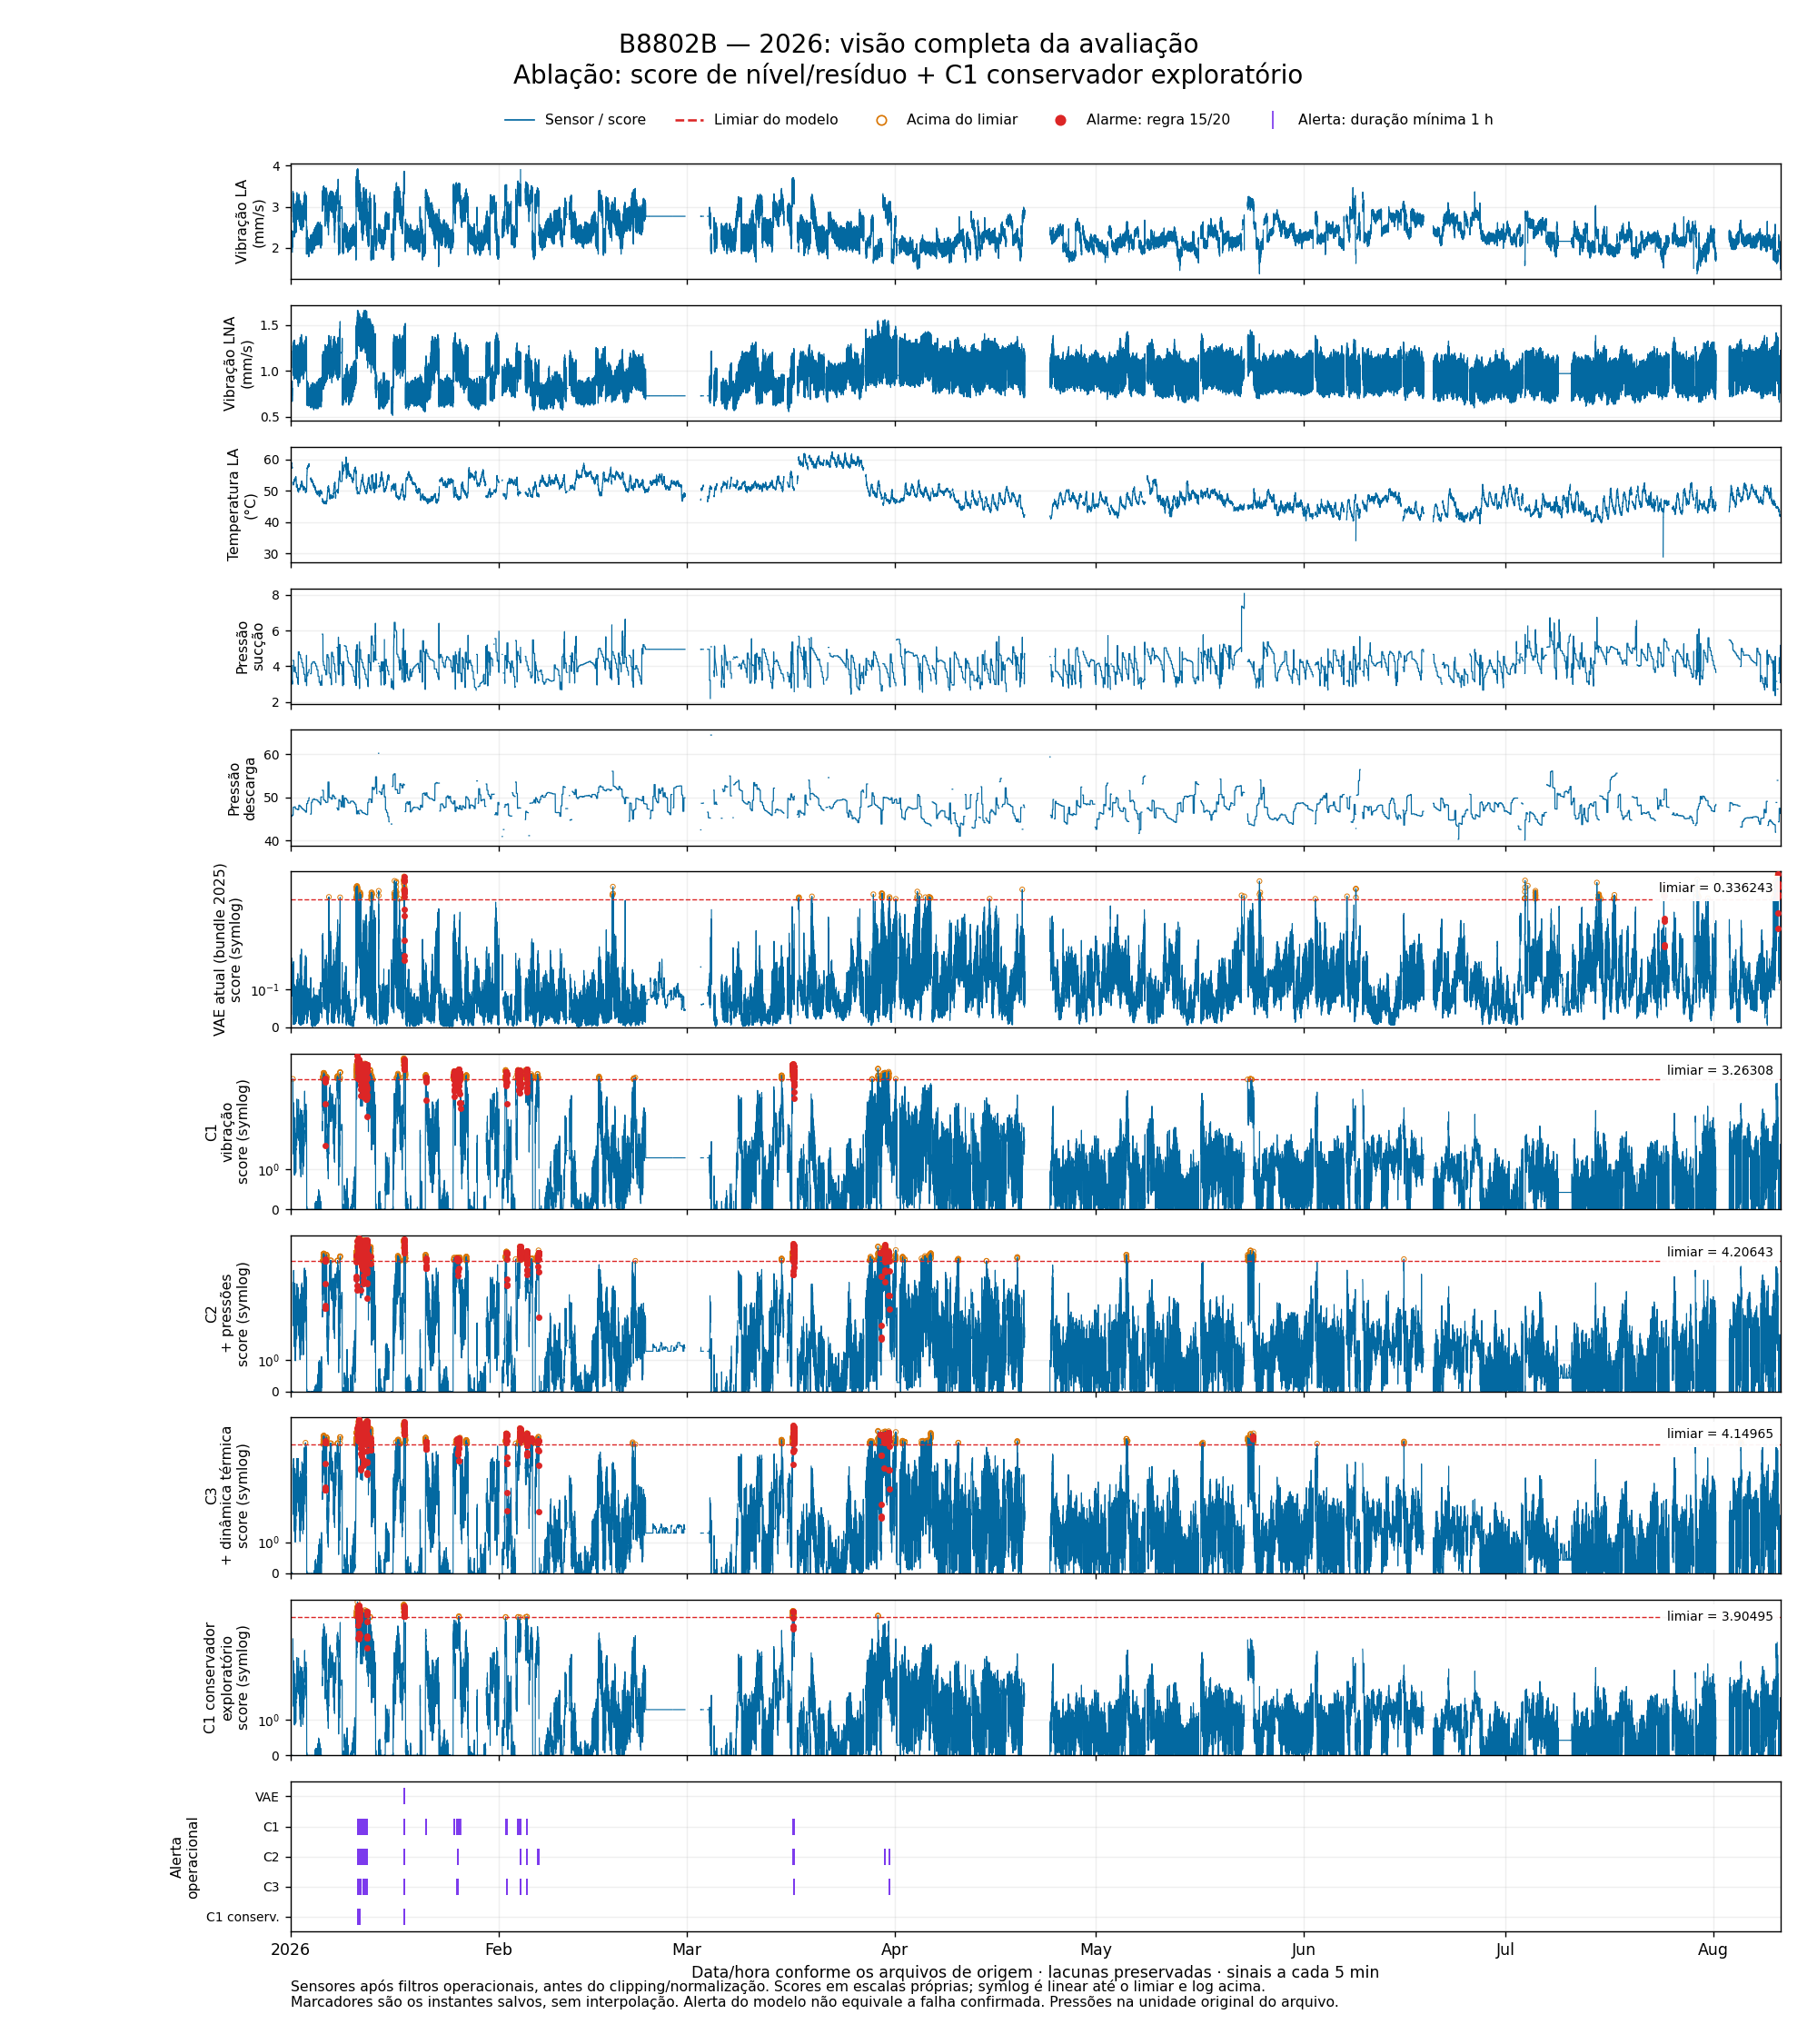

,Modelo,Limiar,Acima do limiar (pontos válidos),Alarme (pontos),Alerta (pontos),Horas com flag de alerta,Primeiro alerta na janela
0,VAE atual (bundle 2025),0.336243,254,29,3,0.250000,2026-01-17 22:30:00
1,C1 · vibração,3.263078,1200,673,456,38.000000,2026-01-10 23:40:00
2,C2 · + pressões,4.206434,1316,559,331,27.583333,2026-01-10 23:40:00
3,C3 · + dinâmica térmica,4.149655,1420,571,335,27.916667,2026-01-10 23:40:00
4,C1 conservador · exploratório,3.904949,259,117,75,6.250000,2026-01-11 00:15:00


In [2]:
fig, audit = plot_window(data, 'recent', '2026-01-01', '2026-08-11', design='levels', title='2026: visão completa da avaliação')
show_figure(fig)
display(window_summary(data, 'recent', '2026-01-01', '2026-08-11', design='levels'))

## Janeiro de 2026: onde os modelos divergem

Os candidatos da ablação sinalizam mais instantes que o VAE. Isso não permite classificá-los como falhas ou falsos positivos sem a operação.

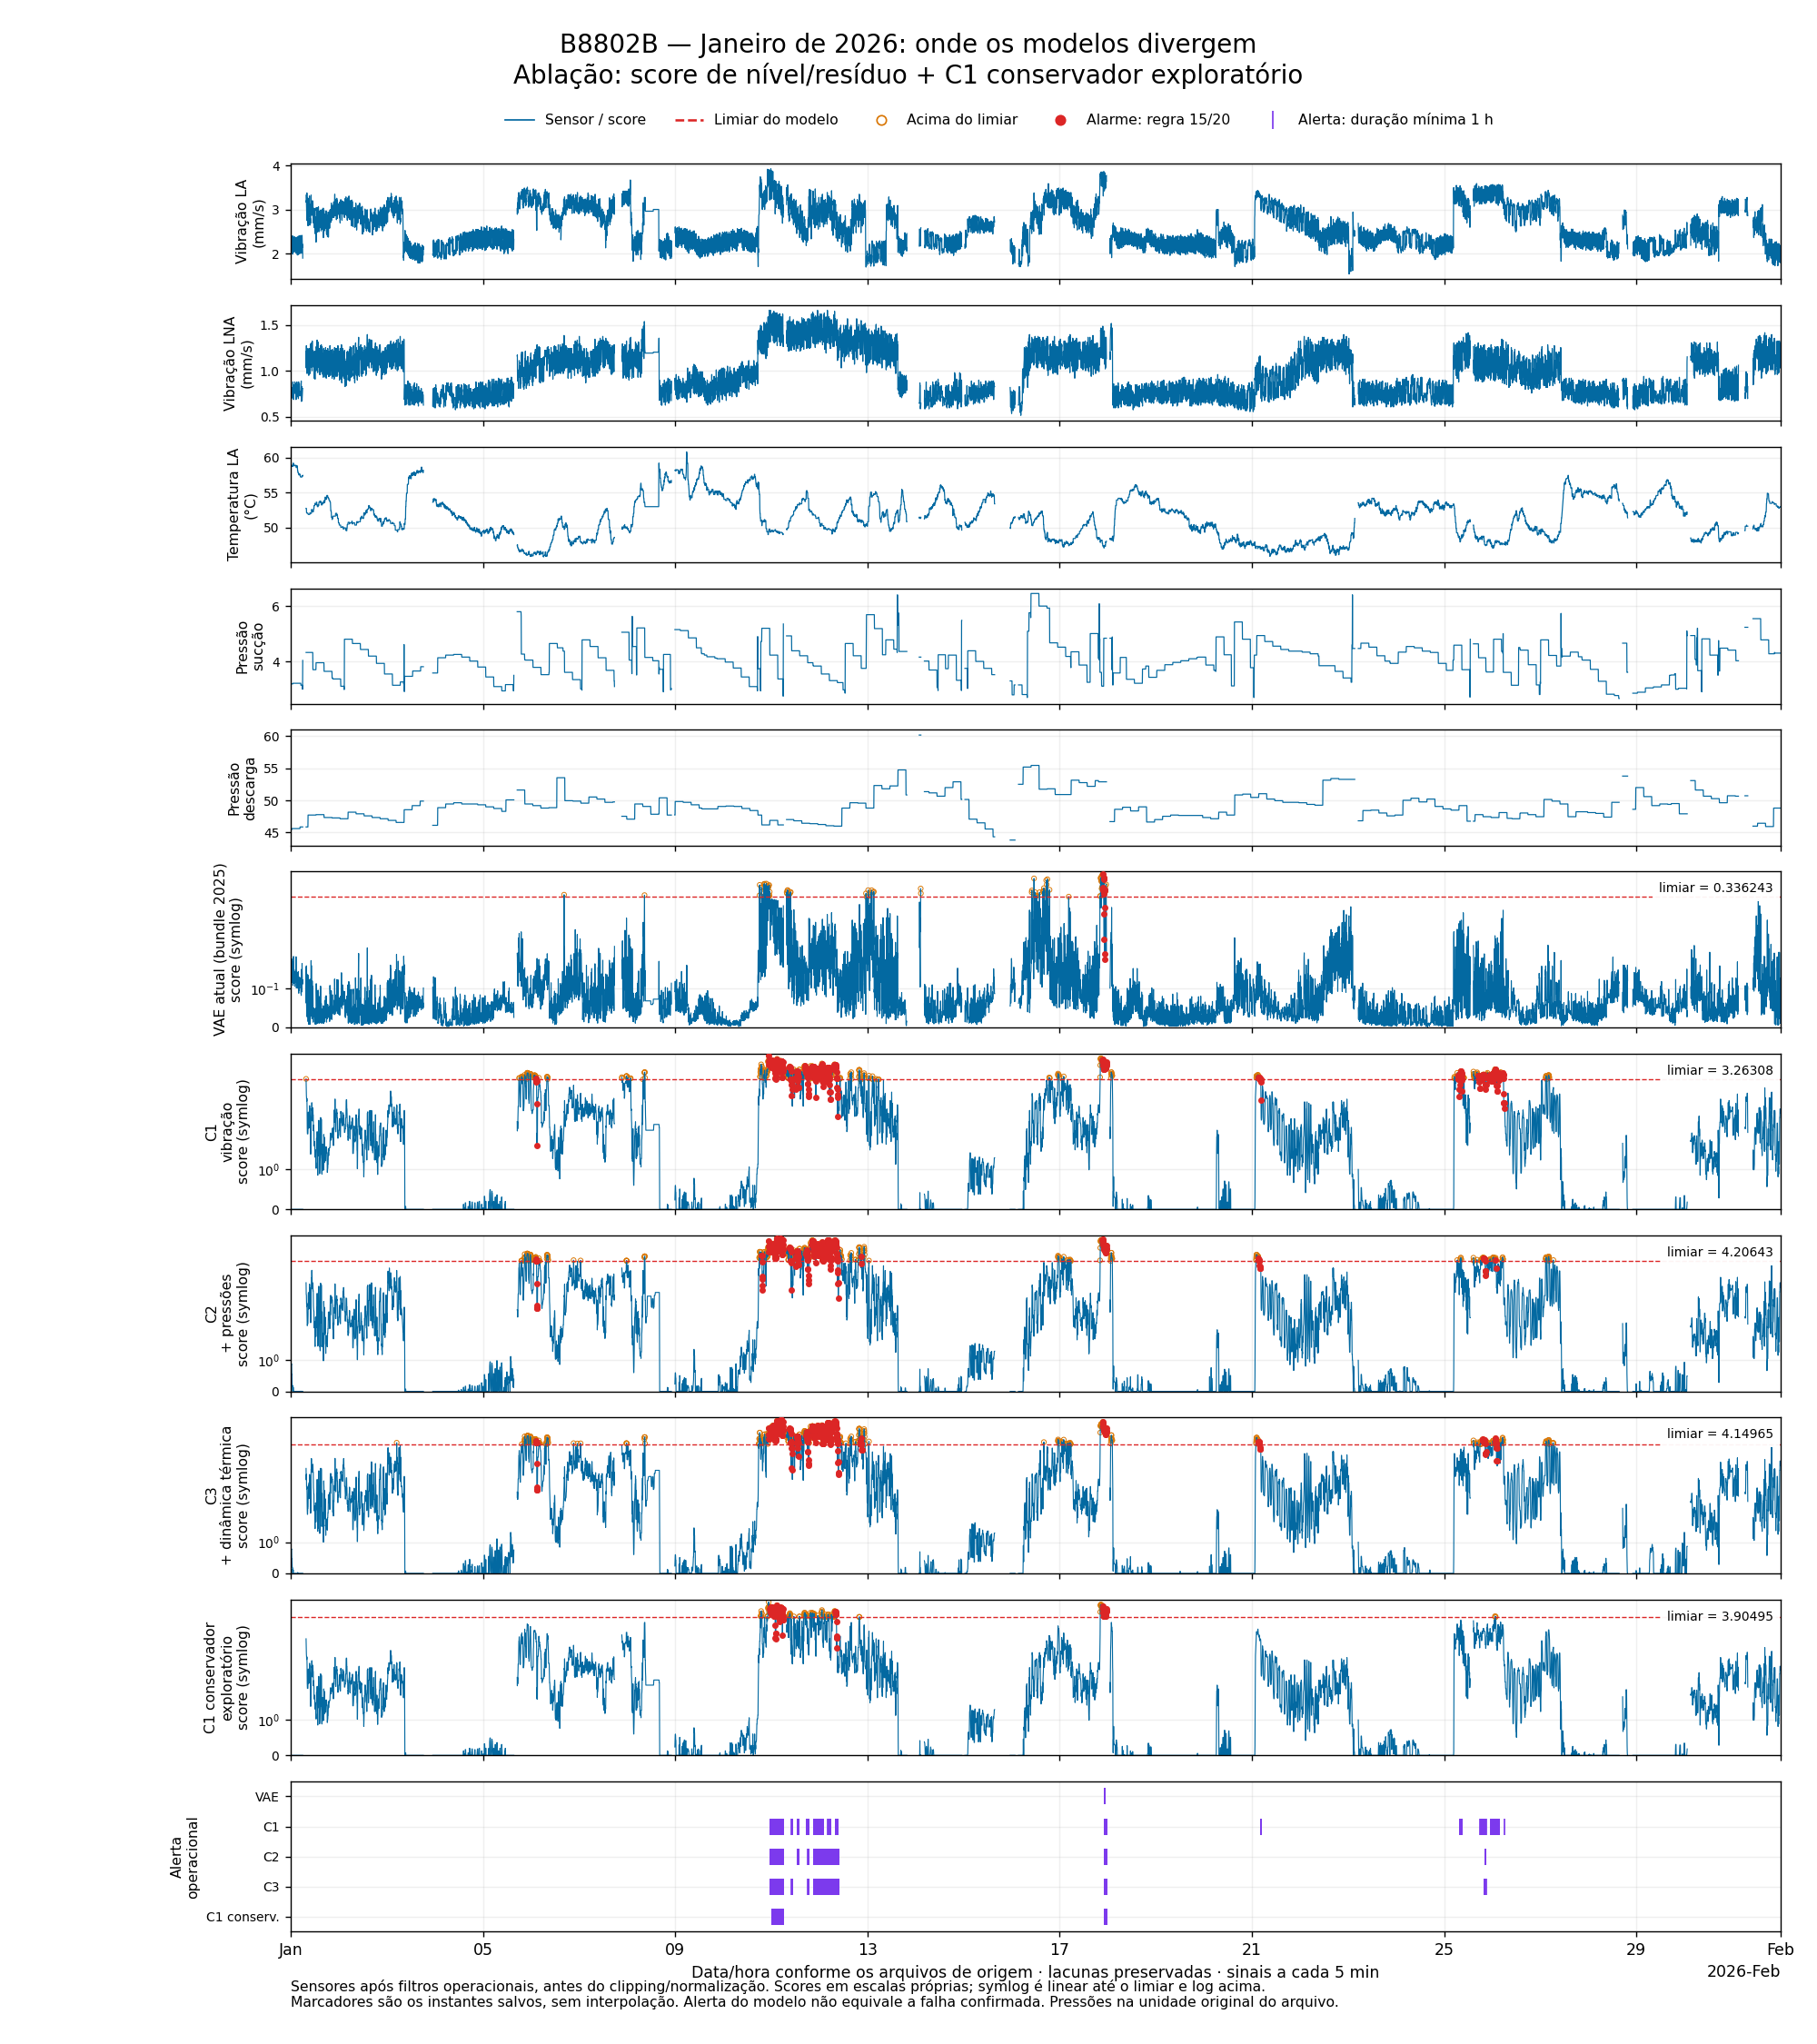

,Modelo,Limiar,Acima do limiar (pontos válidos),Alarme (pontos),Alerta (pontos),Horas com flag de alerta,Primeiro alerta na janela
0,VAE atual (bundle 2025),0.336243,98,15,3,0.250000,2026-01-17 22:30:00
1,C1 · vibração,3.263078,758,459,297,24.750000,2026-01-10 23:40:00
2,C2 · + pressões,4.206434,666,366,251,20.916667,2026-01-10 23:40:00
3,C3 · + dinâmica térmica,4.149655,701,383,258,21.500000,2026-01-10 23:40:00
4,C1 conservador · exploratório,3.904949,216,111,75,6.250000,2026-01-11 00:15:00


In [3]:
fig, audit = plot_window(data, 'recent', '2026-01-01', '2026-02-01', design='levels', title='Janeiro de 2026: onde os modelos divergem')
show_figure(fig)
display(window_summary(data, 'recent', '2026-01-01', '2026-02-01', design='levels'))

## 11/jan: episódio adicional do C1 conservador

O C1 conservador registra 5,25 horas com flag de alerta, entre 00:15 e 06:00 de 11/jan, com interrupções. O VAE não gera alerta operacional nessa janela. O evento precisa de classificação operacional.

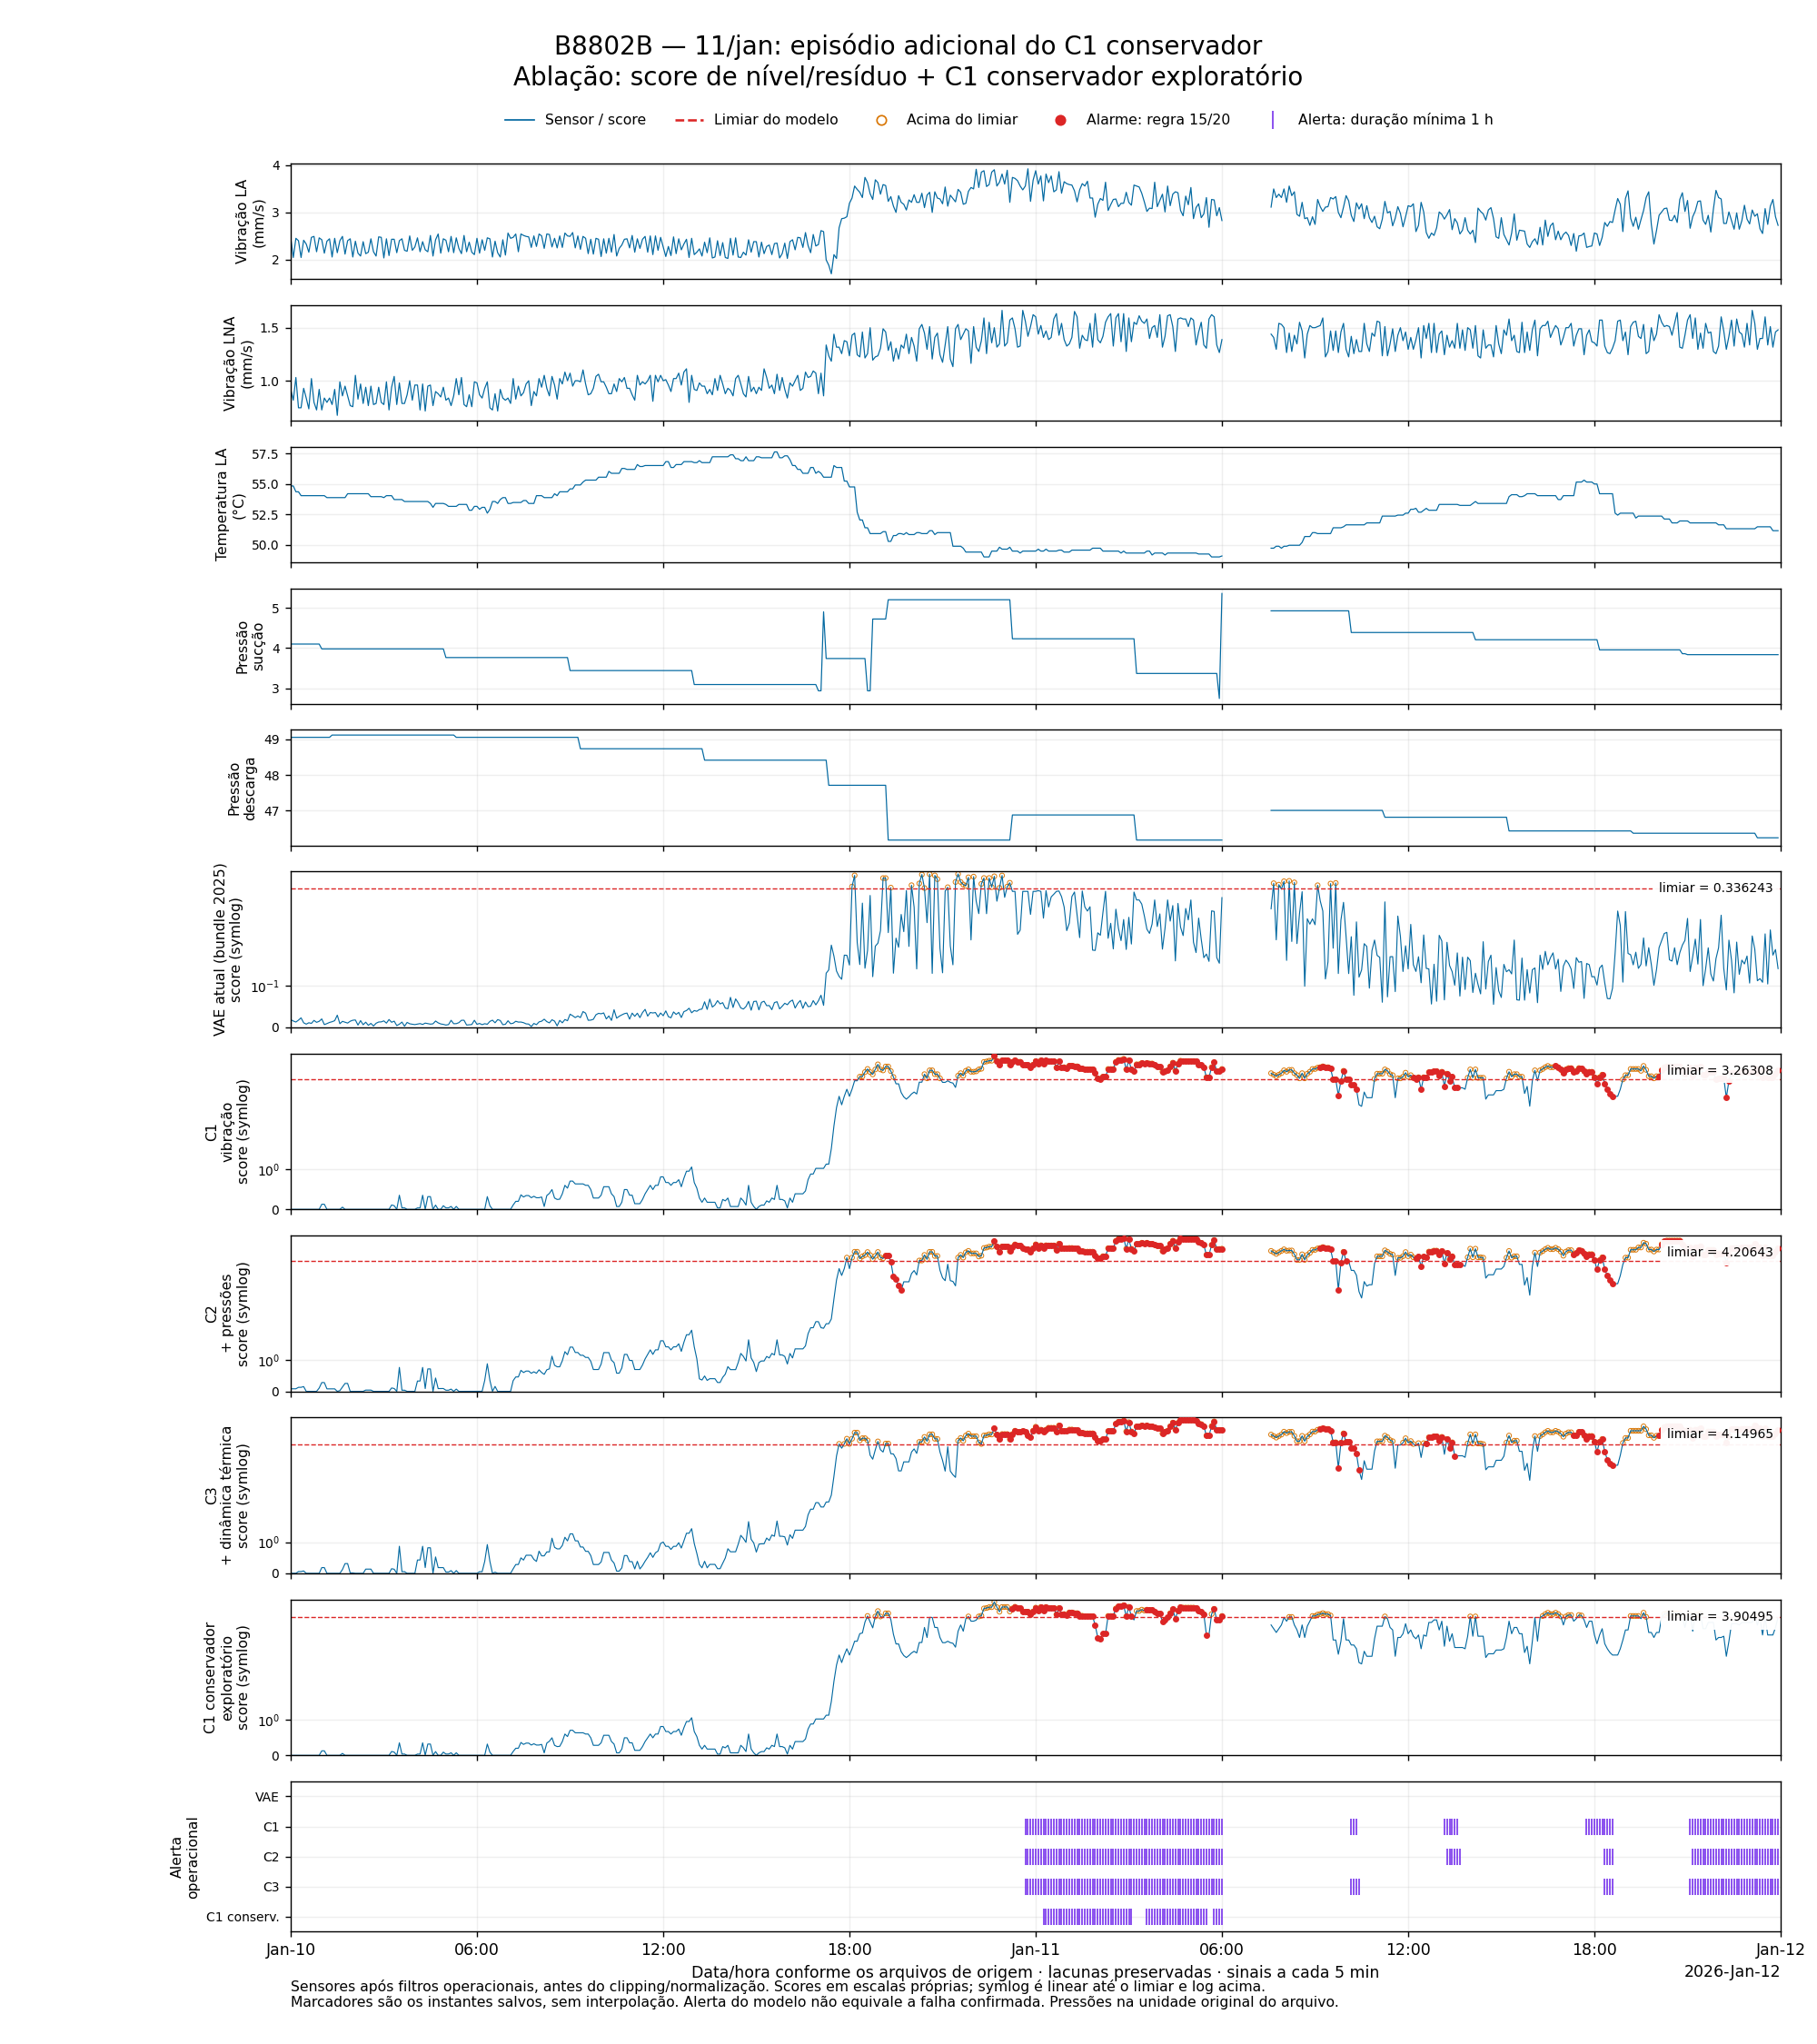

,Modelo,Limiar,Acima do limiar (pontos válidos),Alarme (pontos),Alerta (pontos),Horas com flag de alerta,Primeiro alerta na janela
0,VAE atual (bundle 2025),0.336243,37,0,0,0.000000,—
1,C1 · vibração,3.263078,278,192,132,11.000000,2026-01-10 23:40:00
2,C2 · + pressões,4.206434,275,187,121,10.083333,2026-01-10 23:40:00
3,C3 · + dinâmica térmica,4.149655,276,179,120,10.000000,2026-01-10 23:40:00
4,C1 conservador · exploratório,3.904949,133,75,63,5.250000,2026-01-11 00:15:00


In [4]:
fig, audit = plot_window(data, 'recent', '2026-01-10', '2026-01-12', design='levels', title='11/jan: episódio adicional do C1 conservador')
show_figure(fig)
display(window_summary(data, 'recent', '2026-01-10', '2026-01-12', design='levels'))

## 17/jan: episódio também sinalizado pelo VAE

Compare o crescimento da vibração com a entrada e a duração de cada sinalização. Pontos acima do limiar e alerta operacional são etapas diferentes.

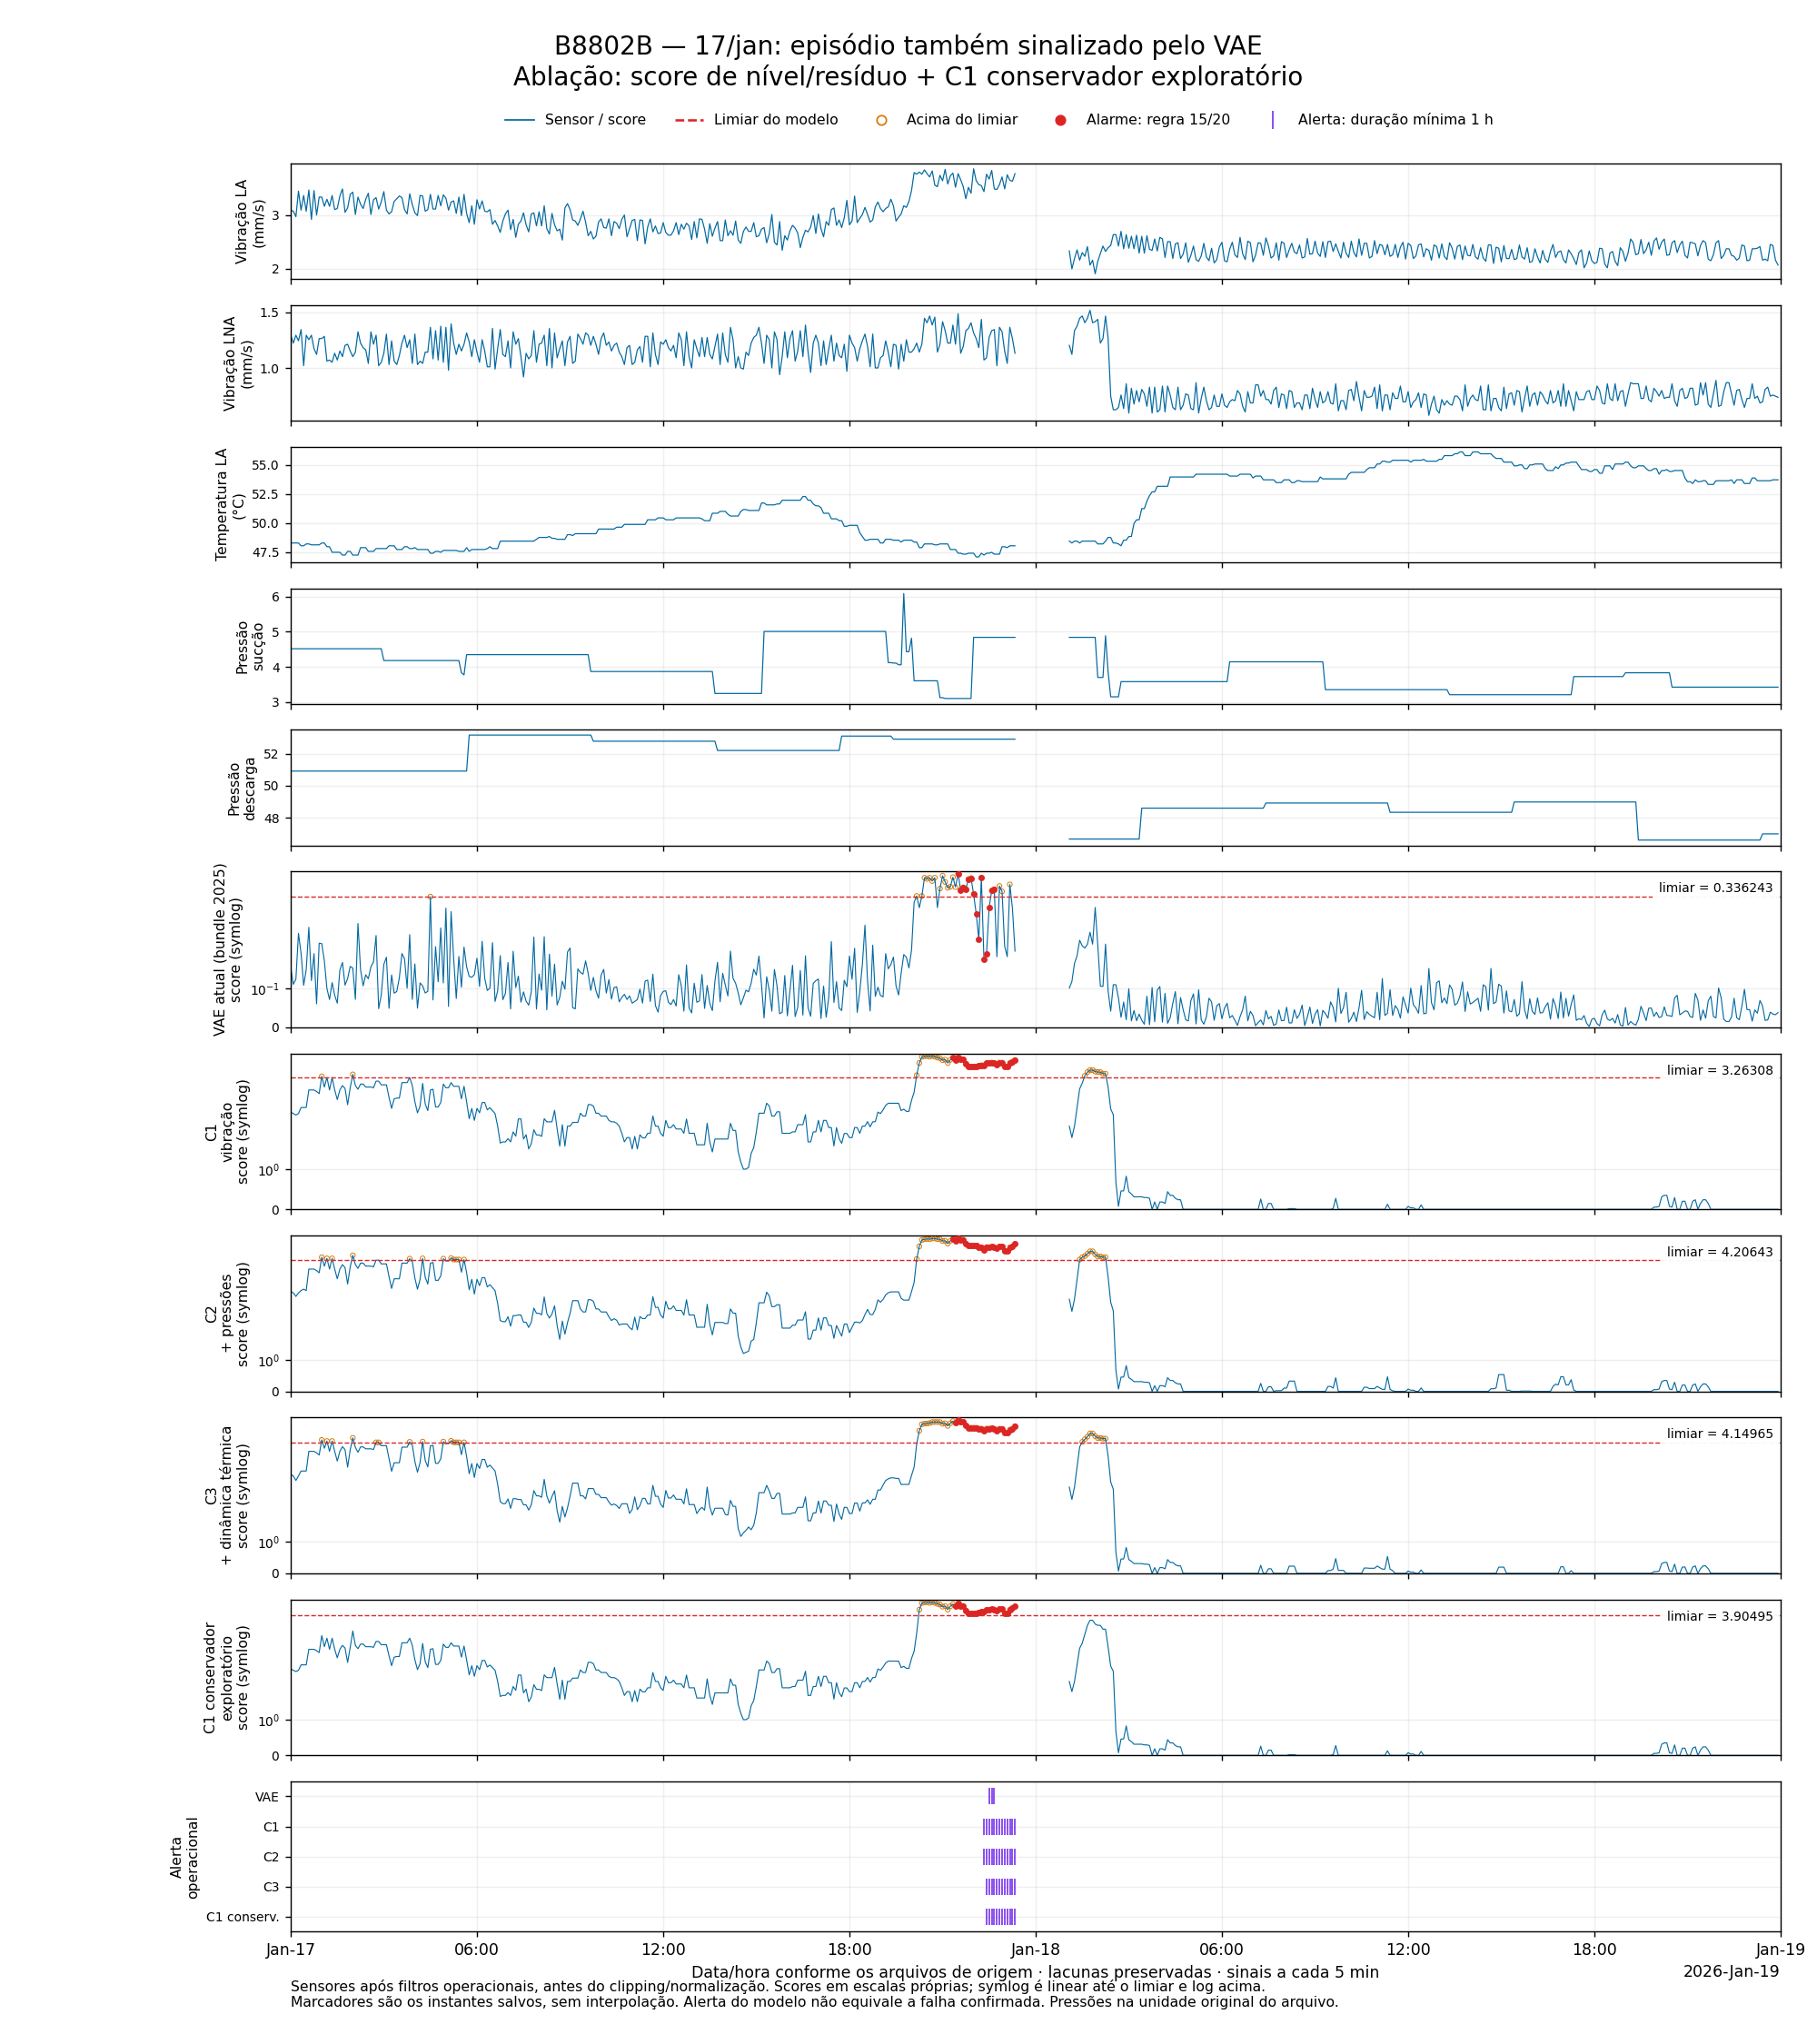

,Modelo,Limiar,Acima do limiar (pontos válidos),Alarme (pontos),Alerta (pontos),Horas com flag de alerta,Primeiro alerta na janela
0,VAE atual (bundle 2025),0.336243,28,15,3,0.250000,2026-01-17 22:30:00
1,C1 · vibração,3.263078,50,25,13,1.083333,2026-01-17 22:20:00
2,C2 · + pressões,4.206434,62,25,13,1.083333,2026-01-17 22:20:00
3,C3 · + dinâmica térmica,4.149655,62,24,12,1.000000,2026-01-17 22:25:00
4,C1 conservador · exploratório,3.904949,38,24,12,1.000000,2026-01-17 22:25:00


In [5]:
fig, audit = plot_window(data, 'recent', '2026-01-17', '2026-01-19', design='levels', title='17/jan: episódio também sinalizado pelo VAE')
show_figure(fig)
display(window_summary(data, 'recent', '2026-01-17', '2026-01-19', design='levels'))

## 2022: histórico anterior e falha conhecida

A linha vertical marca a falha conhecida de 06/jul às 10:00. Alertas anteriores fora da aproximação da falha precisam ser examinados; o primeiro alerta de C3 não comprova maior antecipação útil.

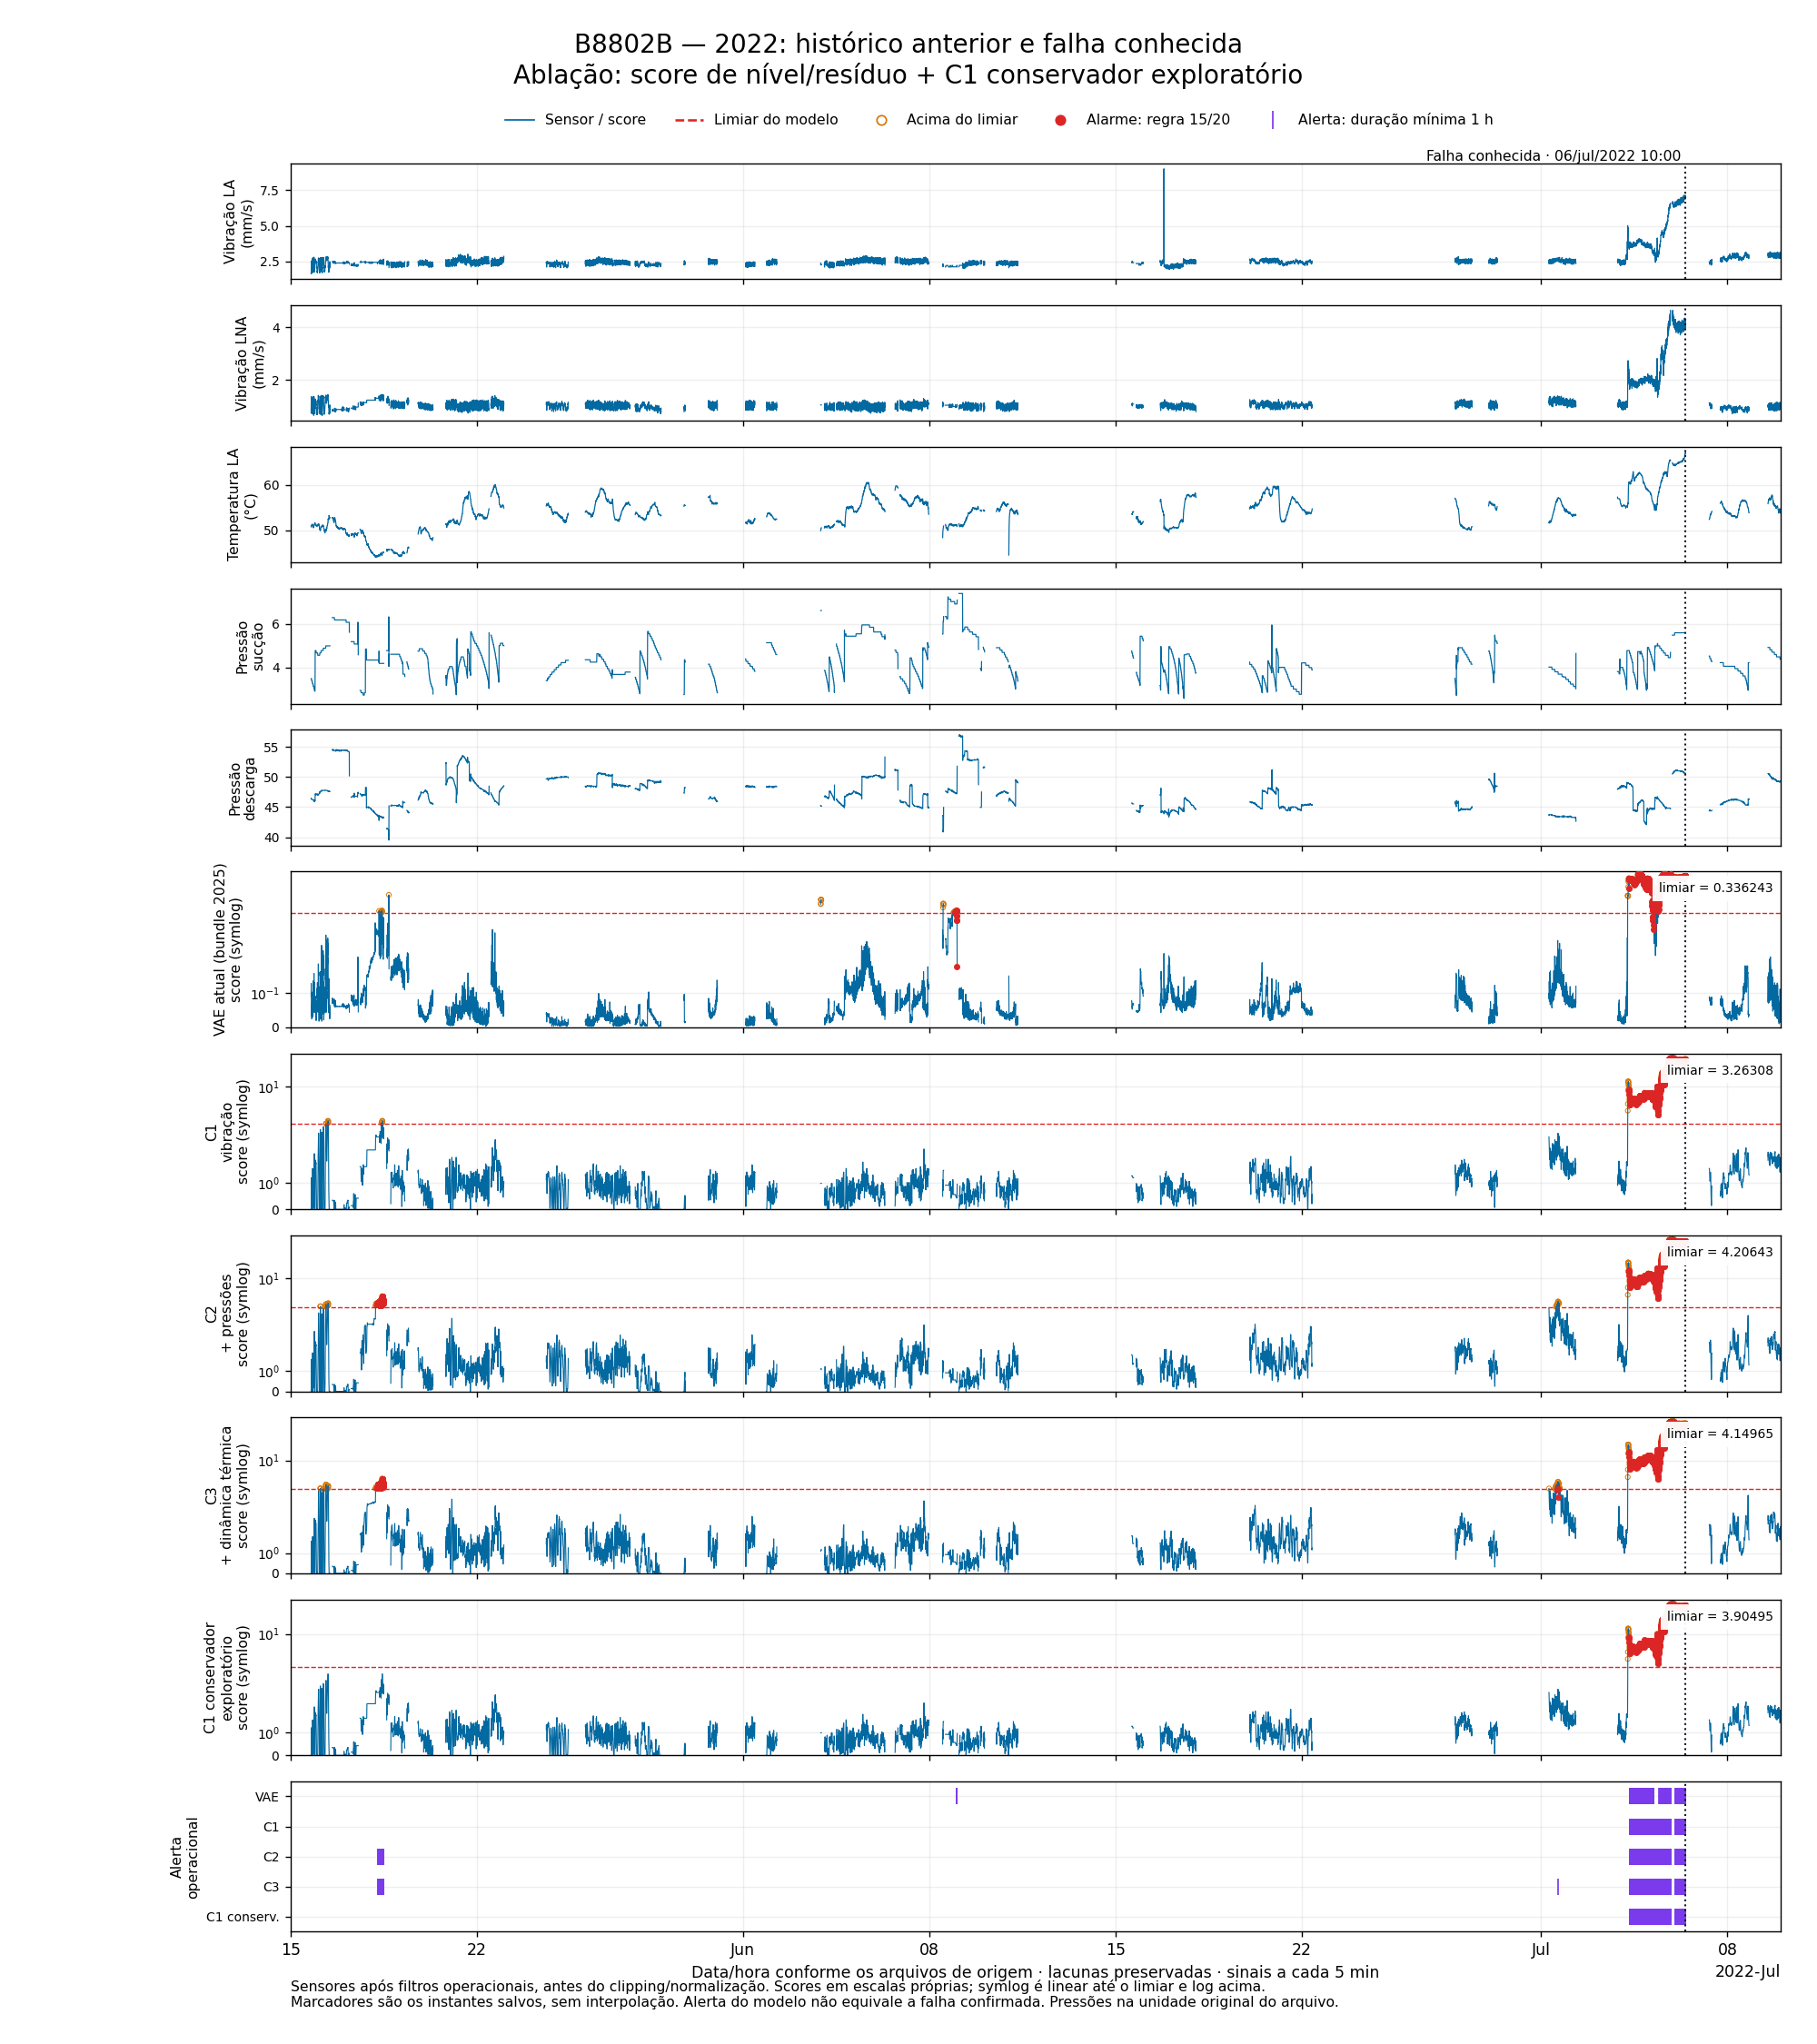

,Modelo,Limiar,Acima do limiar (pontos válidos),Alarme (pontos),Alerta (pontos),Horas com flag de alerta,Primeiro alerta na janela
0,VAE atual (bundle 2025),0.336243,625,545,497,41.416667,2022-06-09 00:25:00
1,C1 · vibração,3.263078,623,574,550,45.833333,2022-07-04 08:15:00
2,C2 · + pressões,4.206434,728,649,613,51.083333,2022-05-18 06:45:00
3,C3 · + dinâmica térmica,4.149655,750,653,614,51.166667,2022-05-18 06:45:00
4,C1 conservador · exploratório,3.904949,607,574,550,45.833333,2022-07-04 08:15:00


In [6]:
fig, audit = plot_window(data, 'old', '2022-05-15', '2022-07-10', design='levels', title='2022: histórico anterior e falha conhecida')
show_figure(fig)
display(window_summary(data, 'old', '2022-05-15', '2022-07-10', design='levels'))

## 2022: aproximação da falha conhecida

C1 conservador preserva aproximadamente 49,75 h de antecedência. Este replay histórico já foi explorado e não constitui um teste independente.

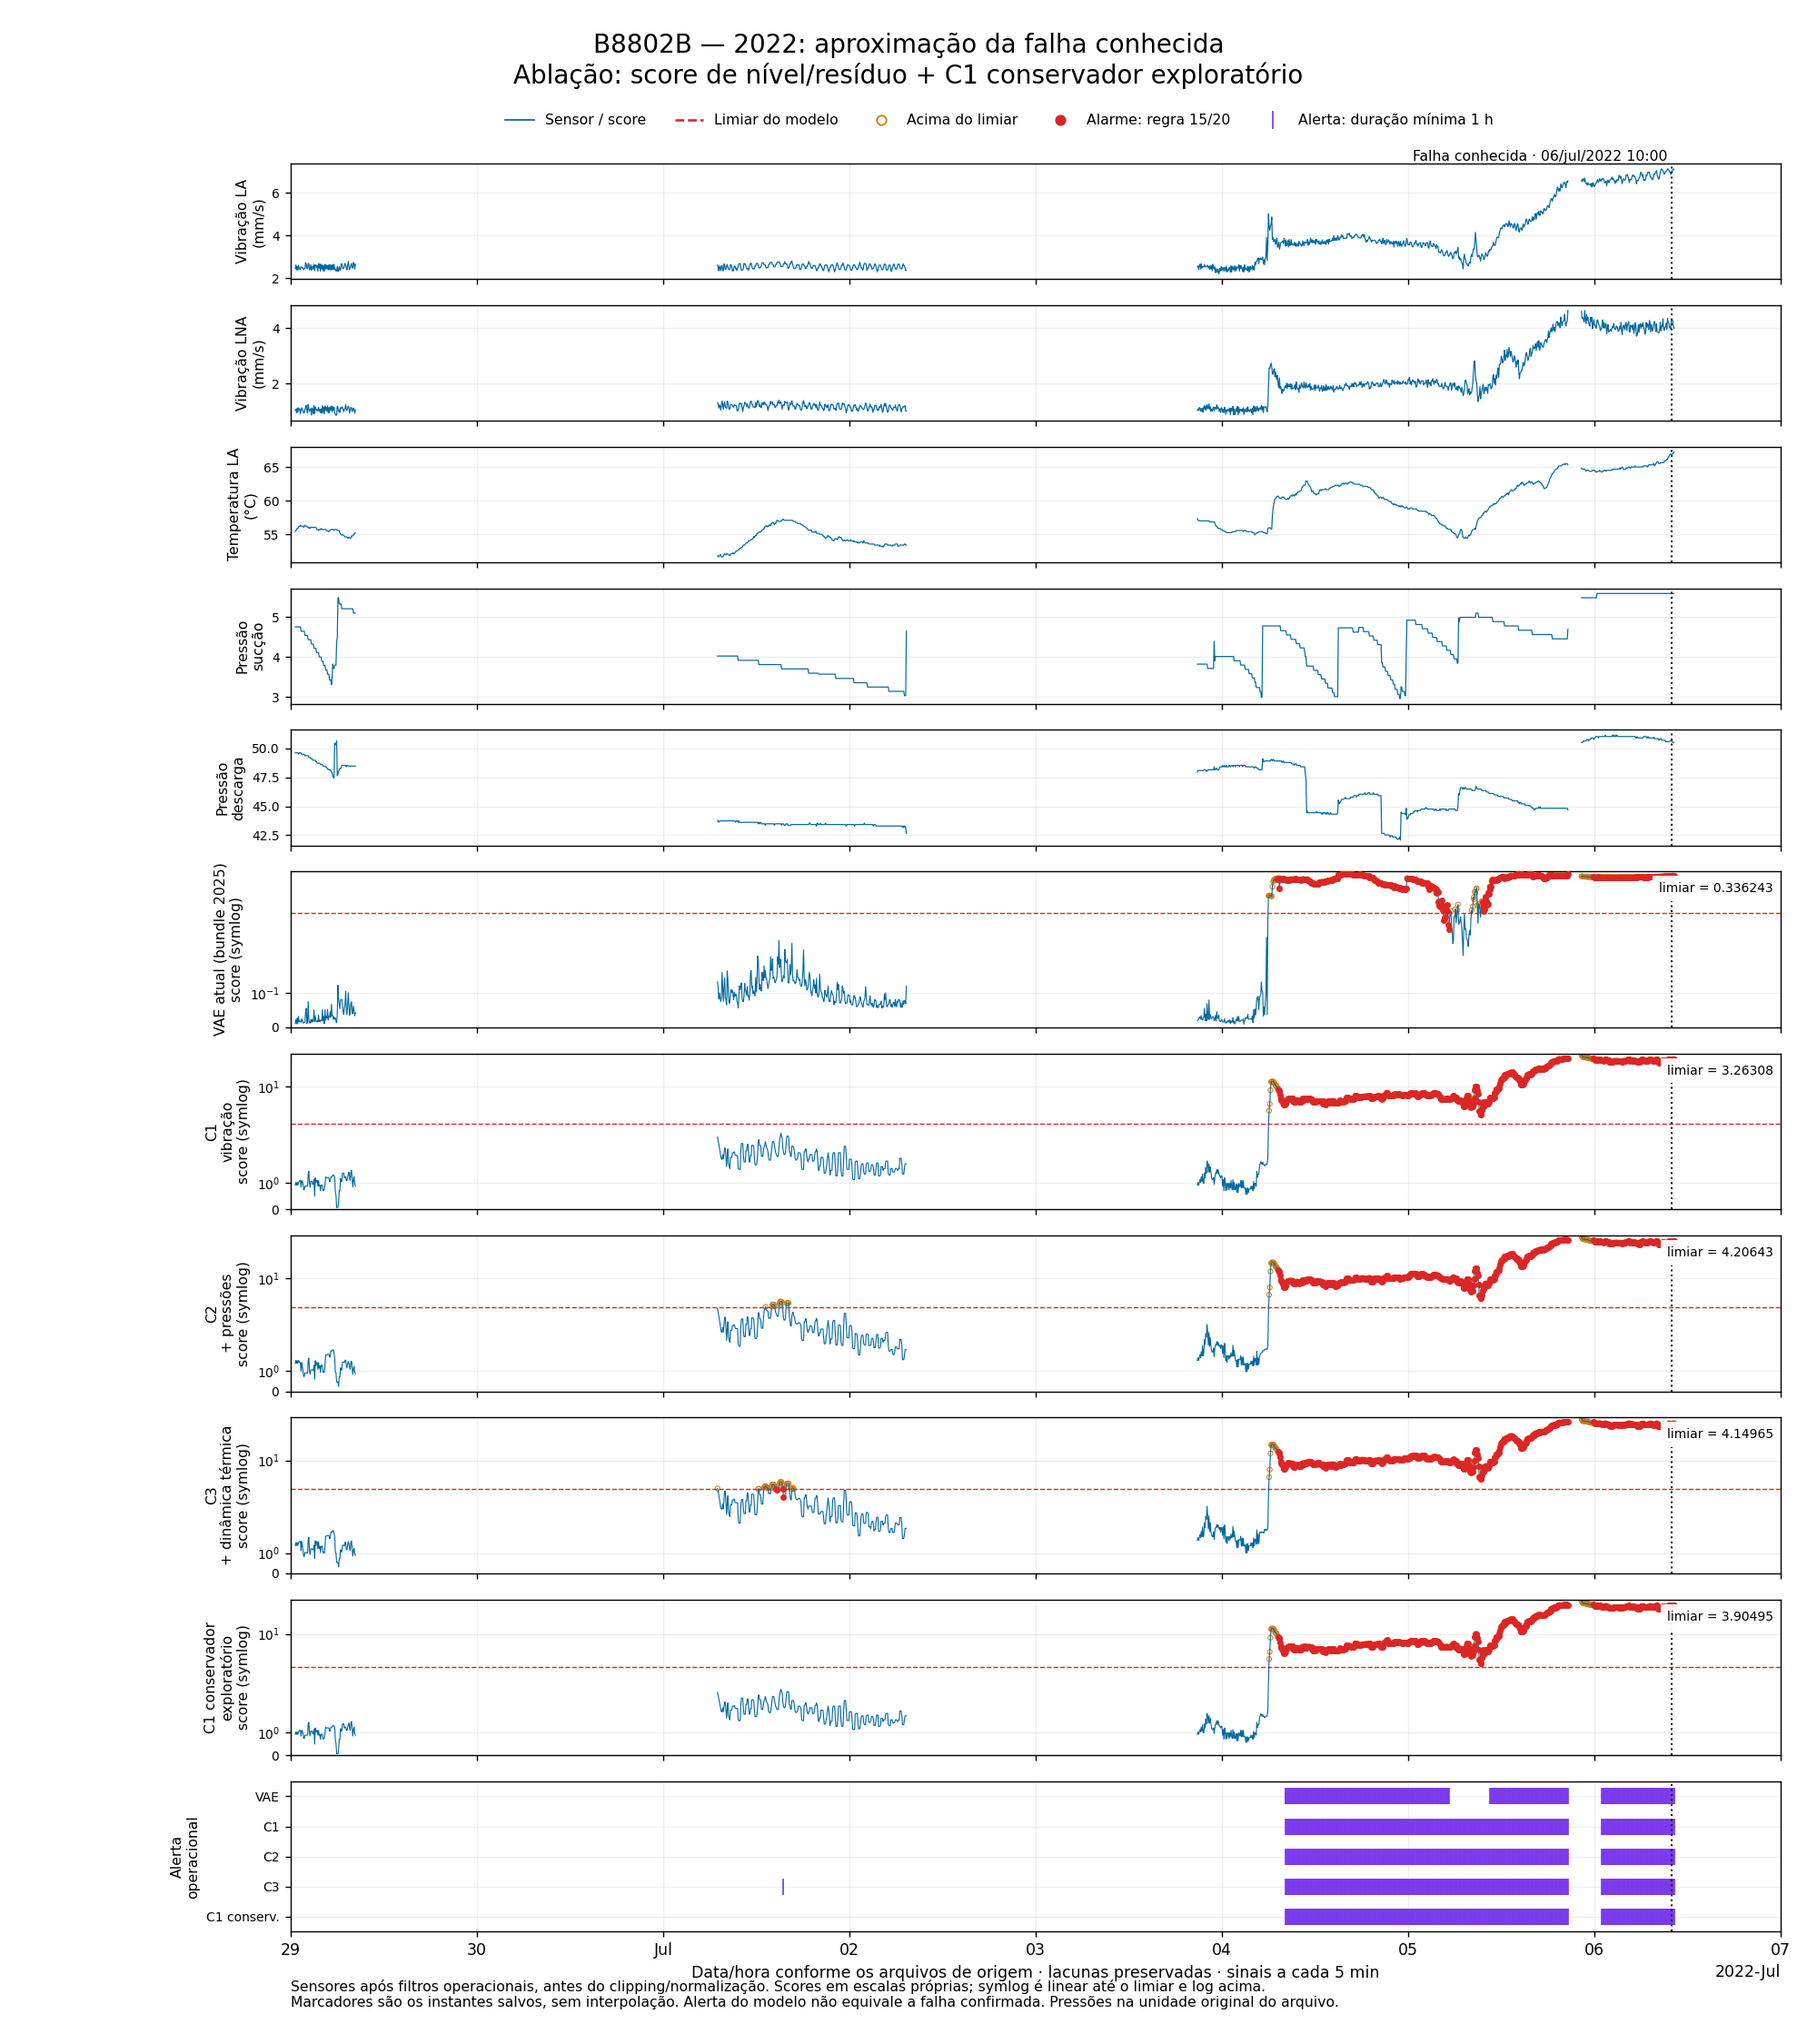

,Modelo,Limiar,Acima do limiar (pontos válidos),Alarme (pontos),Alerta (pontos),Horas com flag de alerta,Primeiro alerta na janela
0,VAE atual (bundle 2025),0.336243,570,524,488,40.666667,2022-07-04 08:10:00
1,C1 · vibração,3.263078,607,574,550,45.833333,2022-07-04 08:15:00
2,C2 · + pressões,4.206434,623,574,550,45.833333,2022-07-04 08:15:00
3,C3 · + dinâmica térmica,4.149655,641,578,551,45.916667,2022-07-01 15:30:00
4,C1 conservador · exploratório,3.904949,607,574,550,45.833333,2022-07-04 08:15:00


In [7]:
fig, audit = plot_window(data, 'old', '2022-06-29', '2022-07-07', design='levels', title='2022: aproximação da falha conhecida')
show_figure(fig)
display(window_summary(data, 'old', '2022-06-29', '2022-07-07', design='levels'))

## Primeira montagem: nível + tendência, janeiro

Esta é a primeira rodada, antes da ablação. Seus candidatos perderam o evento de janeiro; os limiares mais altos ajudam a visualizar o motivo.

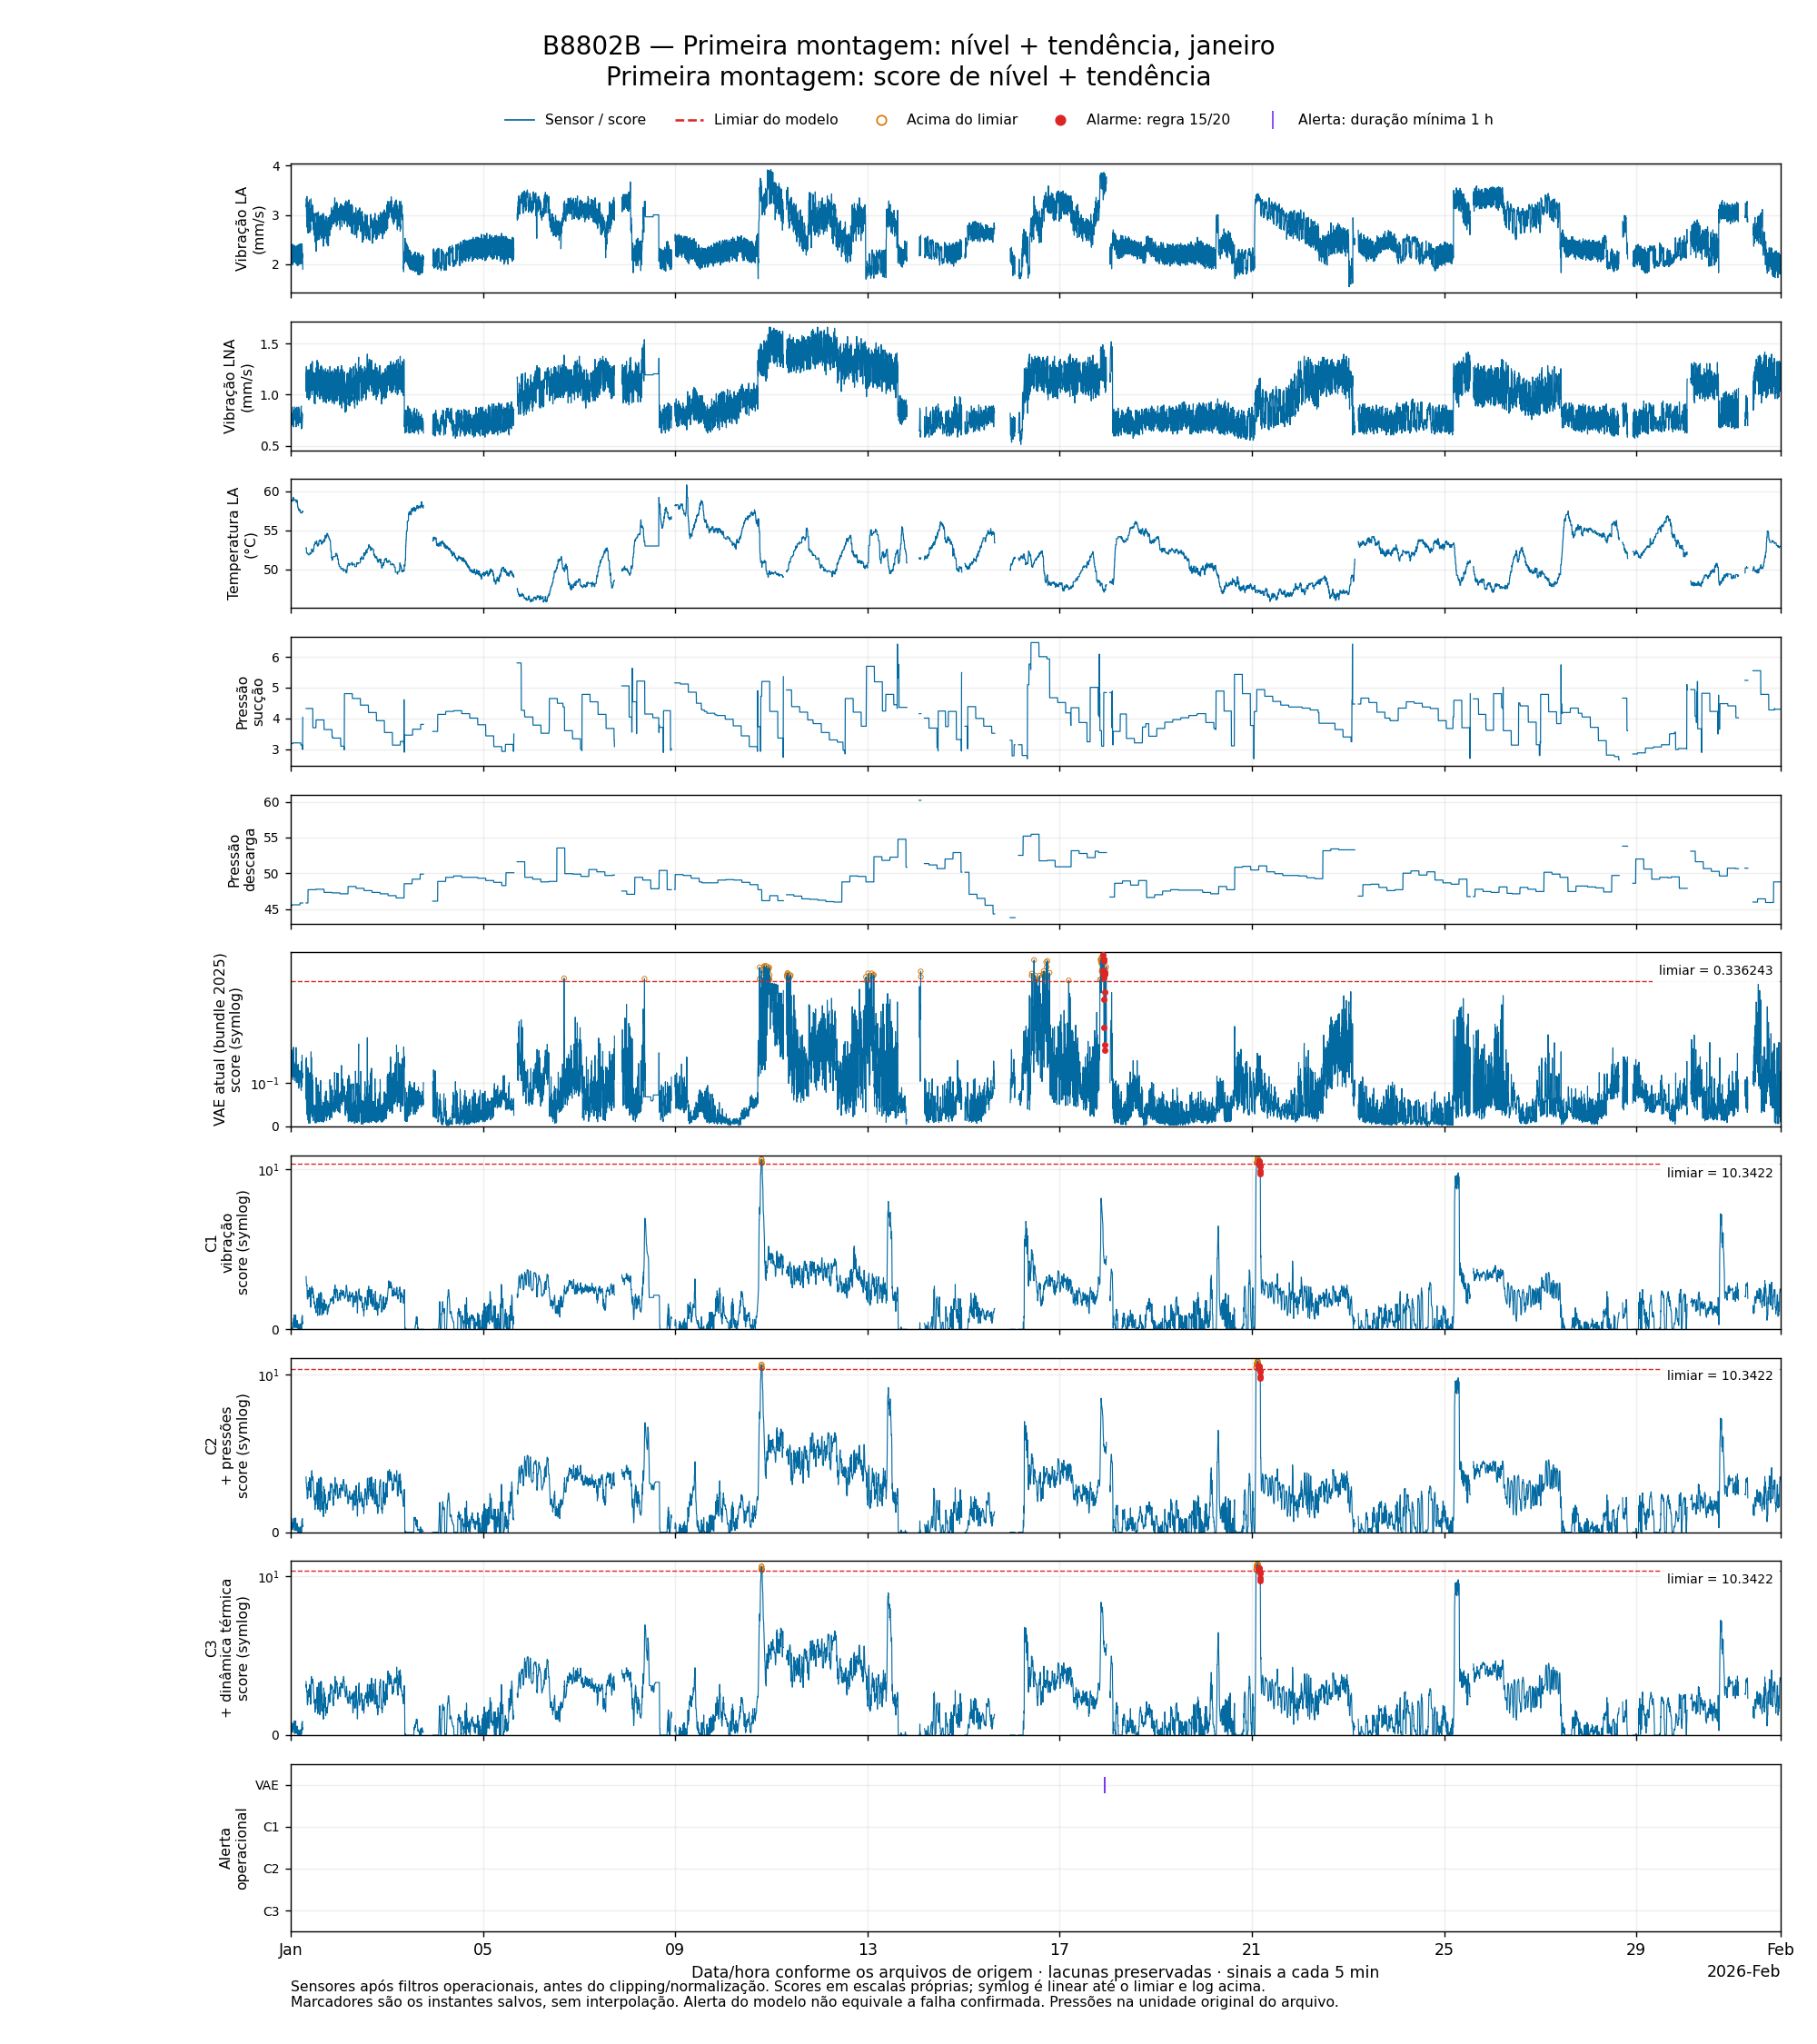

,Modelo,Limiar,Acima do limiar (pontos válidos),Alarme (pontos),Alerta (pontos),Horas com flag de alerta,Primeiro alerta na janela
0,VAE atual (bundle 2025),0.336243,98,15,3,0.25,2026-01-17 22:30:00
1,C1 · vibração,10.342183,24,8,0,0.00,—
2,C2 · + pressões,10.342183,27,11,0,0.00,—
3,C3 · + dinâmica térmica,10.342183,27,11,0,0.00,—


In [8]:
fig, audit = plot_window(data, 'recent', '2026-01-01', '2026-02-01', design='initial', title='Primeira montagem: nível + tendência, janeiro')
show_figure(fig)
display(window_summary(data, 'recent', '2026-01-01', '2026-02-01', design='initial'))

## Primeira montagem: nível + tendência, falha

A primeira montagem ainda sinaliza a falha forte de 2022. Preservar esse evento isolado não foi suficiente para aprovar os candidatos.

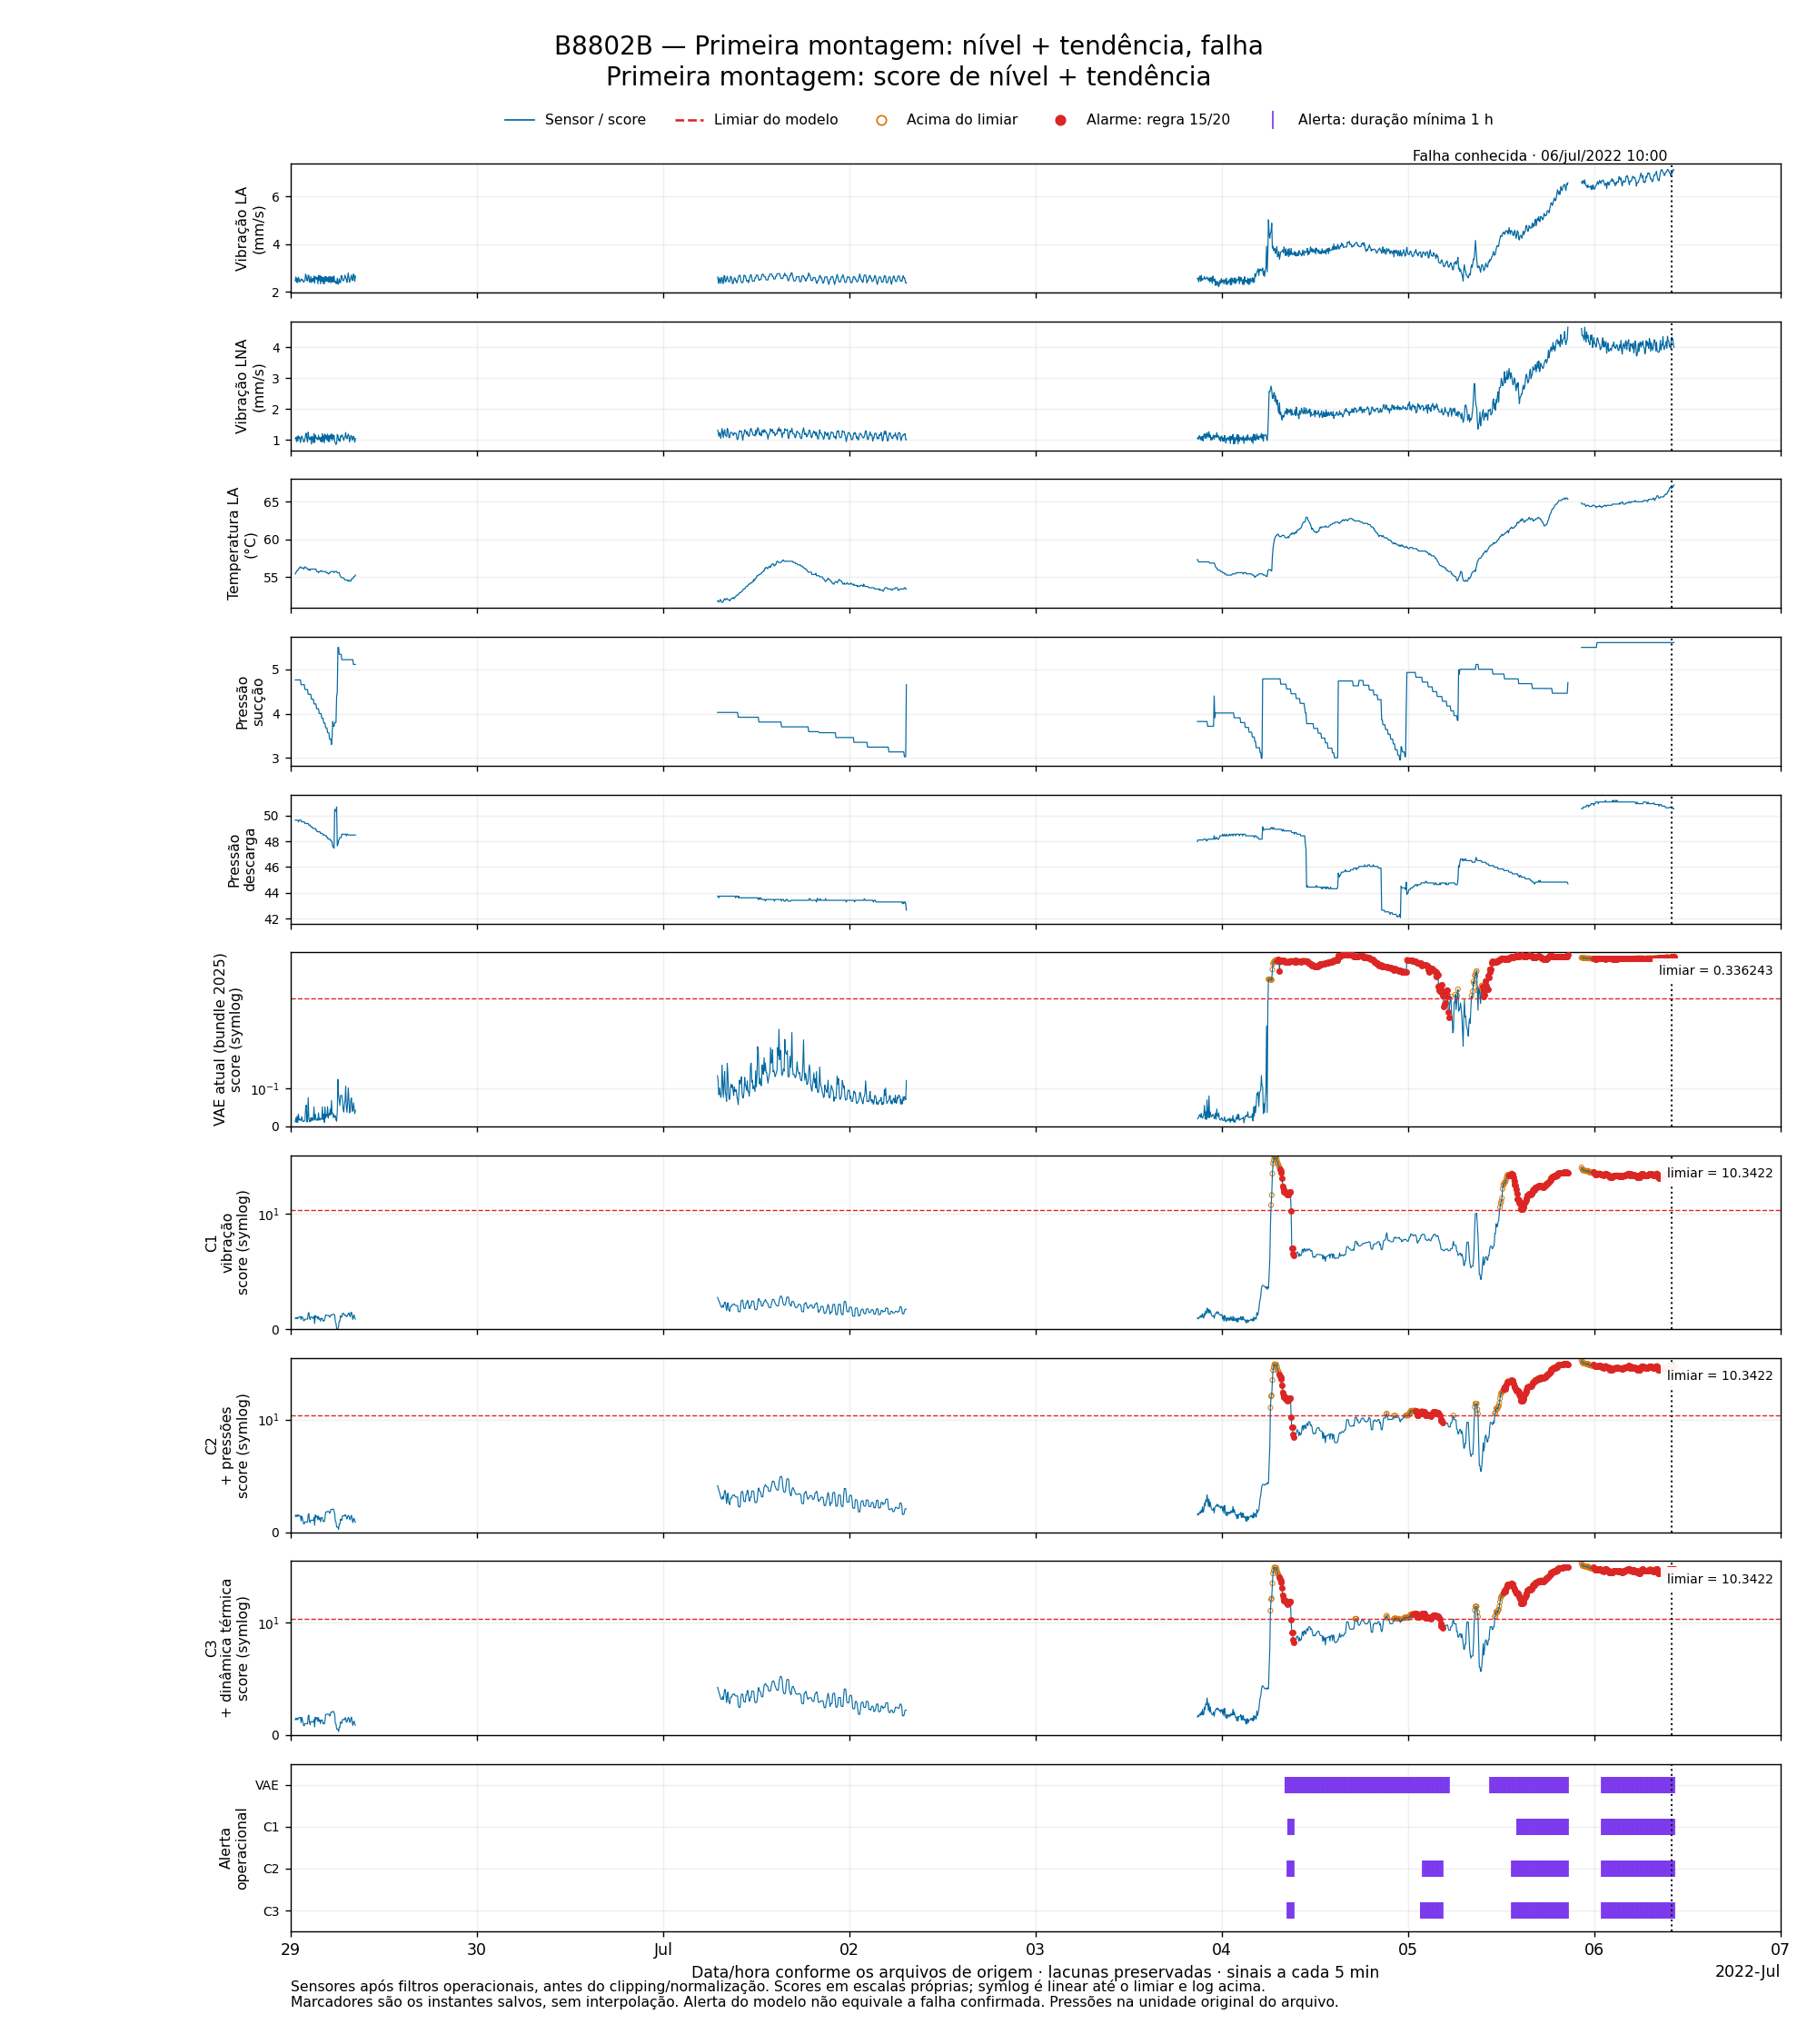

,Modelo,Limiar,Acima do limiar (pontos válidos),Alarme (pontos),Alerta (pontos),Horas com flag de alerta,Primeiro alerta na janela
0,VAE atual (bundle 2025),0.336243,570,524,488,40.666667,2022-07-04 08:10:00
1,C1 · vibração,10.342183,281,239,203,16.916667,2022-07-04 08:30:00
2,C2 · + pressões,10.342183,353,291,243,20.250000,2022-07-04 08:25:00
3,C3 · + dinâmica térmica,10.342183,367,295,247,20.583333,2022-07-04 08:25:00


In [9]:
fig, audit = plot_window(data, 'old', '2022-06-29', '2022-07-07', design='initial', title='Primeira montagem: nível + tendência, falha')
show_figure(fig)
display(window_summary(data, 'old', '2022-06-29', '2022-07-07', design='initial'))

## Explorar outra janela

Edite as datas abaixo e execute a célula. Use `period='old'` para 2022 ou `period='recent'` para 2025–2026. `design='initial'` seleciona a primeira montagem; `design='levels'`, a ablação.

In [10]:
# fig, audit = plot_window(data, 'recent', '2026-06-01', '2026-07-01', title='Junho de 2026')
# show_figure(fig)